In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("paper_style.mplstyle")
from paper_palette import (
    MORPHO_COLOR, AAVE_COLOR,
    WHALE_COLOR, RETAILER_COLOR,
    ALLOCATION_COLORS, ALLOCATION_LABELS,
    PROTOCOL_GROUP_COLORS,
)


In [2]:
CSV_FILES = {
    "syrupUSDC": "../from_dune/morpho_syrup_full_panel.csv",
    "sUSDS":     "../from_dune/morpho_susds_full_panel.csv",
    "sUSDe":     "../from_dune/morpho_aave_susde_full_panel.csv",
}

WALLET_COL = "YBS_wallet_balance"
PROTOCOL_COLS = ["YBS_in_morpho", "YBS_in_aave"]
ADDRESS_COL = "wallet"

PROTOCOL_HEAVY_THRESHOLD = 0.90

In [3]:
dfs = {}
for name, path in CSV_FILES.items():
    df = pd.read_csv(path)
    df["asset"] = name
    dfs[name] = df

all_df = pd.concat(dfs.values(), ignore_index=True)
all_df.shape

(12682, 6)

In [4]:
EPSILON = 1e-3

def classify(row):
    protocol_bal = row["YBS_in_morpho"] + row["YBS_in_aave"]
    total = row["total_YBS_exposure"]

    if total <= 0:
        return "unknown"

    protocol_bal = 0 if abs(protocol_bal) < EPSILON else protocol_bal

    if protocol_bal == 0:
        return "undeployed"

    protocol_pct = protocol_bal / total

    if protocol_pct > 0.90:
        return "fully_deployed"

    return "partially_deployed"

all_df["archetype"] = all_df.apply(classify, axis=1)
all_df["archetype"].value_counts()

archetype
undeployed            11069
fully_deployed         1479
partially_deployed      134
Name: count, dtype: int64

In [5]:
for name, df in dfs.items():
    df["category"] = df.apply(classify, axis=1)
    print(f"--- {name} ---")
    print(df["category"].value_counts())

--- syrupUSDC ---
category
undeployed            1924
fully_deployed          78
partially_deployed       5
Name: count, dtype: int64
--- sUSDS ---
category
undeployed            3135
fully_deployed          93
partially_deployed      14
Name: count, dtype: int64
--- sUSDe ---
category
undeployed            6010
fully_deployed        1308
partially_deployed     115
Name: count, dtype: int64


In [6]:
summary = (
    all_df
    .groupby(["asset", "archetype"])
    .agg(
        wallets=("wallet", "count"),
        total_exposure=("total_YBS_exposure", "sum"),
    )
    .reset_index()
)

summary["pct_of_wallets"] = (
    summary["wallets"] / summary.groupby("asset")["wallets"].transform("sum") * 100
)
summary["pct_of_exposure"] = (
    summary["total_exposure"] / summary.groupby("asset")["total_exposure"].transform("sum") * 100
)

summary.sort_values(["asset", "total_exposure"], ascending=[True, False])

,asset,archetype,wallets,total_exposure,pct_of_wallets,pct_of_exposure
2,sUSDS,undeployed,3135,3.943055e+09,96.699568,98.433965
0,sUSDS,fully_deployed,93,6.144713e+07,2.868600,1.533959
1,sUSDS,partially_deployed,14,1.284881e+06,0.431832,0.032076
5,sUSDe,undeployed,6010,1.213273e+09,80.855644,57.201653
3,sUSDe,fully_deployed,1308,8.994248e+08,17.597202,42.404795
4,sUSDe,partially_deployed,115,8.347405e+06,1.547155,0.393552
8,syrupUSDC,undeployed,1924,1.097373e+09,95.864474,90.208648
6,syrupUSDC,fully_deployed,78,1.191100e+08,3.886398,9.791337
7,syrupUSDC,partially_deployed,5,1.887814e+02,0.249128,0.000016


In [7]:
def protocol_type(row):
    morpho = 0 if abs(row["YBS_in_morpho"]) < EPSILON else row["YBS_in_morpho"]
    aave = 0 if abs(row["YBS_in_aave"]) < EPSILON else row["YBS_in_aave"]

    if morpho > 0 and aave > 0:
        return "both"
    elif morpho > 0:
        return "morpho"
    elif aave > 0:
        return "aave"
    else:
        return "none"

for name, df in dfs.items():
    df["protocol_type"] = df.apply(protocol_type, axis=1)

In [8]:
colors = {
    "spot_hold":              ALLOCATION_COLORS["spot_hold"],
    "mix_allocation":         ALLOCATION_COLORS["mix_allocation"],
    "mix_allocation_morpho":  MORPHO_COLOR,
    "mix_allocation_aave":    AAVE_COLOR,
    "fully_allocated":        ALLOCATION_COLORS["fully_allocated"],
    "fully_allocated_morpho": MORPHO_COLOR,
    "fully_allocated_aave":   AAVE_COLOR,
}

labels = {
    "spot_hold": "Spot hold / Other protocols",
    "mix_allocation": "Mix allocation",
    "mix_allocation_morpho": "Mix allocation (Morpho)",
    "mix_allocation_aave": "Mix allocation (Aave)",
    "fully_allocated": "Fully allocated to Aave/Morpho",
    "fully_allocated_morpho": "Fully allocated (Morpho)",
    "fully_allocated_aave": "Fully allocated (Aave)",
}


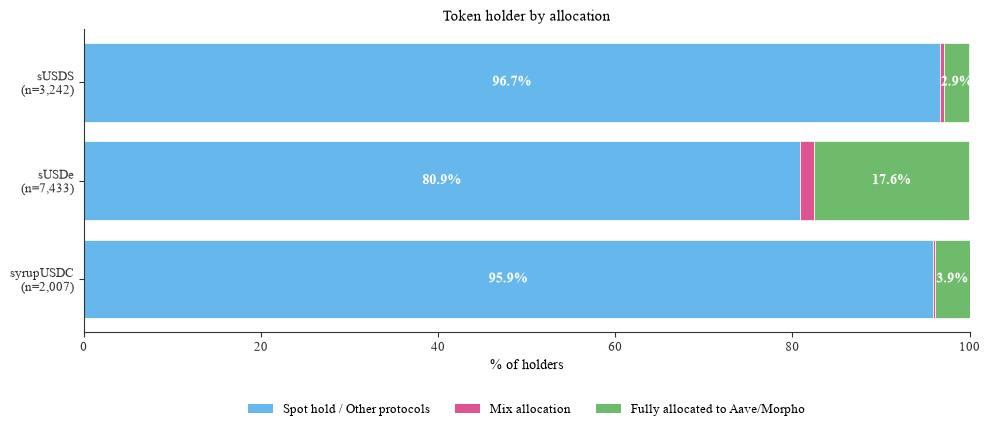

In [9]:
simple_colors = ALLOCATION_COLORS
simple_labels = ALLOCATION_LABELS
asset_order = ["syrupUSDC", "sUSDe", "sUSDS"]

# Maps the old category names in your data to the new display names
category_rename = {
    "undeployed": "spot_hold",
    "partially_deployed": "mix_allocation",
    "fully_deployed": "fully_allocated",
}

def build_simple_segments(name, df):
    n = len(df)
    mapped_category = df["category"].map(category_rename)
    segs = {
        "spot_hold":          (mapped_category == "spot_hold").sum(),
        "mix_allocation":     (mapped_category == "mix_allocation").sum(),
        "fully_allocated":    (mapped_category == "fully_allocated").sum(),
    }
    return segs, n

segment_data = {}
for name in asset_order:
    segs, n = build_simple_segments(name, dfs[name])
    segment_data[name] = {"segs": segs, "n": n}

fig, ax = plt.subplots(figsize=(10, 4.5))
y_positions = range(len(asset_order))

for y, name in zip(y_positions, asset_order):
    segs = segment_data[name]["segs"]
    n = segment_data[name]["n"]
    left = 0

    for seg_name in ["spot_hold", "mix_allocation", "fully_allocated"]:
        count = segs[seg_name]
        if count == 0:
            continue
        pct = count / n * 100
        ax.barh(y, pct, left=left, color=simple_colors[seg_name], edgecolor="white", linewidth=0.5)

        if pct >= 2.5:
            ax.text(left + pct / 2, y, f"{pct:.1f}%", ha="center", va="center",
            color="white", fontweight="bold", fontsize=10)
        left += pct

ax.set_yticks(list(y_positions))
ax.set_yticklabels([f"{name}\n(n={segment_data[name]['n']:,})" for name in asset_order])
ax.set_xlabel("% of holders")
ax.set_xlim(0, 100)
ax.set_title("Token holder by allocation")

handles = [plt.Rectangle((0, 0), 1, 1, color=simple_colors[s]) for s in simple_colors]
ax.legend(handles, [simple_labels[s] for s in simple_colors], loc="upper center",
          bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)

plt.tight_layout()
plt.savefig("../output/holder_meta_archetypes.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
def protocol_group(row):
    m = row["YBS_in_morpho"] > 0
    a = row["YBS_in_aave"] > 0
    if m and a:
        return "Both"
    elif m:
        return "Morpho only"
    elif a:
        return "Aave only"
    else:
        return "Spot held / (other protocols)"

all_df["protocol_group"] = all_df.apply(protocol_group, axis=1)

split_table = (
    all_df.groupby(["asset", "protocol_group"])
    .agg(
        wallets=("wallet", "count"),
        total_value=("total_YBS_exposure", "sum"),
    )
    .reset_index()
)

split_table["pct_wallets"] = split_table.groupby("asset")["wallets"].transform(lambda x: x / x.sum() * 100)
split_table["pct_value"] = split_table.groupby("asset")["total_value"].transform(lambda x: x / x.sum() * 100)

split_table.sort_values(["asset", "protocol_group"])

,asset,protocol_group,wallets,total_value,pct_wallets,pct_value
0,sUSDS,Morpho only,107,6.273201e+07,3.300432,1.566035
1,sUSDS,Spot held / (other protocols),3135,3.943055e+09,96.699568,98.433965
2,sUSDe,Aave only,1222,9.357024e+08,16.440199,44.115160
3,sUSDe,Both,21,4.390312e+07,0.282524,2.069882
4,sUSDe,Morpho only,223,1.593381e+07,3.000135,0.751224
5,sUSDe,Spot held / (other protocols),5967,1.125506e+09,80.277142,53.063734
6,syrupUSDC,Morpho only,83,1.191102e+08,4.135526,9.791352
7,syrupUSDC,Spot held / (other protocols),1924,1.097373e+09,95.864474,90.208648


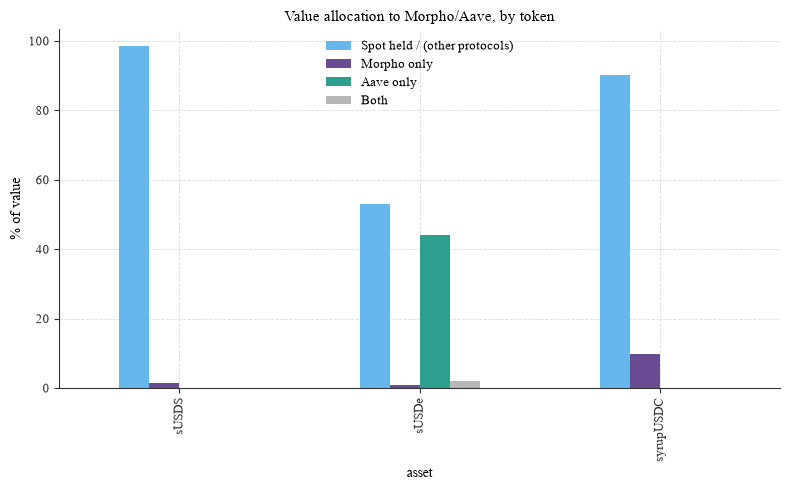

In [11]:

pivot_wallets = split_table.pivot(index="asset", columns="protocol_group", values="pct_wallets").fillna(0)
pivot_value = split_table.pivot(index="asset", columns="protocol_group", values="pct_value").fillna(0)

# reorder columns so legend is consistent
col_order = [c for c in ["Spot held / (other protocols)", "Morpho only", "Aave only", "Both"] if c in pivot_value.columns]
pivot_value = pivot_value[col_order]

fig, ax = plt.subplots(figsize=(8, 5))
pivot_value.plot(kind="bar", ax=ax, color=[PROTOCOL_GROUP_COLORS[c] for c in pivot_value.columns])
ax.set_title("Value allocation to Morpho/Aave, by token")
ax.set_ylabel("% of value")
ax.legend(title="")

plt.tight_layout()
plt.savefig("../output/protocol_split_by_token_value.png", dpi=300, bbox_inches="tight")
plt.show()


In [12]:
WHALE_THRESHOLD = 1_000_000

all_df["is_whale"] = all_df["total_YBS_exposure"] > WHALE_THRESHOLD

whale_concentration = (
    all_df.groupby(["asset", "is_whale"])
    .agg(
        wallets=("wallet", "count"),
        morpho_value=("YBS_in_morpho", "sum"),
        aave_value=("YBS_in_aave", "sum"),
    )
    .reset_index()
)

whale_concentration["pct_wallets"] = whale_concentration.groupby("asset")["wallets"].transform(lambda x: x / x.sum() * 100)
whale_concentration["pct_morpho_value"] = whale_concentration.groupby("asset")["morpho_value"].transform(
    lambda x: x / x.sum() * 100 if x.sum() > 0 else 0
)
whale_concentration["pct_aave_value"] = whale_concentration.groupby("asset")["aave_value"].transform(
    lambda x: x / x.sum() * 100 if x.sum() > 0 else 0
)

whale_concentration

,asset,is_whale,wallets,morpho_value,aave_value,pct_wallets,pct_morpho_value,pct_aave_value
0,sUSDS,False,3046,1.003041e+07,0.000000e+00,93.954349,16.055877,0.000000
1,sUSDS,True,196,5.244148e+07,0.000000e+00,6.045651,83.944123,0.000000
2,sUSDe,False,7294,5.243877e+06,8.526528e+07,98.129961,11.613909,9.948358
3,sUSDe,True,139,3.990782e+07,7.718136e+08,1.870039,88.386091,90.051642
4,syrupUSDC,False,1952,6.208185e+06,0.000000e+00,97.259591,5.214971,0.000000
5,syrupUSDC,True,55,1.128373e+08,0.000000e+00,2.740409,94.785029,0.000000


In [13]:
morpho_whales = all_df[(all_df["is_whale"]) & (all_df["YBS_in_morpho"] > 0)][
    ["wallet", "asset", "YBS_wallet_balance", "YBS_in_morpho", "total_YBS_exposure"]
]
morpho_whales.to_csv("morpho_whales.csv", index=False)
print("Morpho whales:", len(morpho_whales))

Morpho whales: 41


In [14]:
aave_whales = all_df[(all_df["is_whale"]) & (all_df["YBS_in_aave"] > 0)][
    ["wallet", "asset", "YBS_wallet_balance", "YBS_in_aave", "total_YBS_exposure"]
]
aave_whales.to_csv("aave_whales.csv", index=False)
print("Aave whales:", len(aave_whales))

Aave whales: 81


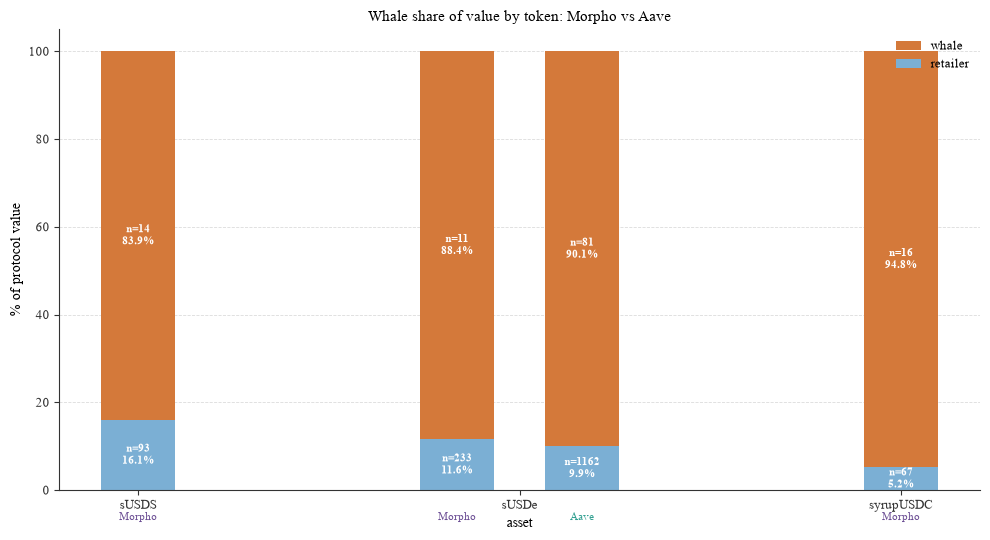

In [15]:
# %% Chart: whale share of Morpho and Aave value (single combined chart)

import numpy as np
from matplotlib.patches import Patch

# wallet counts filtered to only wallets with actual Morpho exposure
morpho_wallets = (
    all_df[all_df["YBS_in_morpho"] > 0]
    .groupby(["asset", "is_whale"])["wallet"].count()
    .reset_index(name="wallets")
)
wallets_pivot_morpho = morpho_wallets.pivot(index="asset", columns="is_whale", values="wallets").fillna(0)
wallets_pivot_morpho.columns = ["non_whale", "whale"]

# wallet counts filtered to only wallets with actual Aave exposure
aave_wallets = (
    all_df[all_df["YBS_in_aave"] > 0]
    .groupby(["asset", "is_whale"])["wallet"].count()
    .reset_index(name="wallets")
)
wallets_pivot_aave = aave_wallets.pivot(index="asset", columns="is_whale", values="wallets").fillna(0)
wallets_pivot_aave.columns = ["non_whale", "whale"]

pivot_morpho = whale_concentration.pivot(index="asset", columns="is_whale", values="pct_morpho_value").fillna(0)
pivot_morpho.columns = ["non_whale", "whale"]

pivot_aave = whale_concentration.pivot(index="asset", columns="is_whale", values="pct_aave_value").fillna(0)
pivot_aave.columns = ["non_whale", "whale"]

# align all pivots to the same asset list
assets = sorted(set(pivot_morpho.index) | set(pivot_aave.index))
pivot_morpho = pivot_morpho.reindex(assets).fillna(0)
pivot_aave = pivot_aave.reindex(assets).fillna(0)
wallets_pivot_morpho = wallets_pivot_morpho.reindex(assets).fillna(0)
wallets_pivot_aave = wallets_pivot_aave.reindex(assets).fillna(0)

# which assets have Aave data
has_aave = {asset: pivot_aave.loc[asset].sum() > 0 for asset in assets}

fig, ax = plt.subplots(figsize=(10, 5.5))

w = 0.35
gap = 0.12

# build x positions: single bar for morpho-only, paired for both
x_morpho = {}
x_aave = {}
pos = 0
for asset in assets:
    if has_aave[asset]:
        x_morpho[asset] = pos - w/2 - gap
        x_aave[asset] = pos + w/2 + gap
    else:
        x_morpho[asset] = pos
    pos += 1.8

# draw Morpho bars
for asset in assets:
    xm = x_morpho[asset]
    nw = pivot_morpho.loc[asset, "non_whale"]
    wh = pivot_morpho.loc[asset, "whale"]
    ax.bar(xm, nw, w, color=RETAILER_COLOR)
    ax.bar(xm, wh, w, bottom=nw, color=WHALE_COLOR)

# draw Aave bars (only where data exists)
for asset in assets:
    if not has_aave[asset]:
        continue
    xa = x_aave[asset]
    nw = pivot_aave.loc[asset, "non_whale"]
    wh = pivot_aave.loc[asset, "whale"]
    ax.bar(xa, nw, w, color=RETAILER_COLOR)
    ax.bar(xa, wh, w, bottom=nw, color=WHALE_COLOR)

# annotate Morpho segments
for asset in assets:
    xm = x_morpho[asset]
    bot = 0
    for col in ["non_whale", "whale"]:
        pct = pivot_morpho.loc[asset, col]
        n = int(wallets_pivot_morpho.loc[asset, col])
        if pct > 3:
            ax.text(xm, bot + pct / 2, f"n={n}\n{pct:.1f}%",
                    ha="center", va="center", color="white",
                    fontweight="bold", fontsize=8)
        bot += pct

# annotate Aave segments
for asset in assets:
    if not has_aave[asset]:
        continue
    xa = x_aave[asset]
    bot = 0
    for col in ["non_whale", "whale"]:
        pct = pivot_aave.loc[asset, col]
        n = int(wallets_pivot_aave.loc[asset, col])
        if pct > 3:
            ax.text(xa, bot + pct / 2, f"n={n}\n{pct:.1f}%",
                    ha="center", va="center", color="white",
                    fontweight="bold", fontsize=8)
        bot += pct

# protocol labels below bars
for asset in assets:
    xm = x_morpho[asset]
    if has_aave[asset]:
        ax.text(xm, -5, "Morpho", ha="center", va="top", fontsize=8, color=MORPHO_COLOR)
        ax.text(x_aave[asset], -5, "Aave", ha="center", va="top", fontsize=8, color=AAVE_COLOR)
    else:
        ax.text(xm, -5, "Morpho", ha="center", va="top", fontsize=8, color=MORPHO_COLOR)

# asset name tick labels
tick_positions = []
for asset in assets:
    if has_aave[asset]:
        tick_positions.append((x_morpho[asset] + x_aave[asset]) / 2)
    else:
        tick_positions.append(x_morpho[asset])

ax.set_xticks(tick_positions)
ax.set_xticklabels(assets)
ax.set_ylim(0, 105)
ax.set_ylabel("% of protocol value")
ax.set_xlabel("asset")
ax.set_title("Whale share of protocol value, by token")
ax.legend(handles=[Patch(color=WHALE_COLOR, label="whale"),
                   Patch(color=RETAILER_COLOR, label="retailer")])

plt.tight_layout()
plt.savefig("../output/whale_concentration_morpho_aave.png", dpi=300, bbox_inches="tight")
plt.show()


In [20]:
# %% Supply, holder counts, and top-holder concentration, per token (with whale count)

WHALE_THRESHOLD = 1_000_000

def gini(values):
    """Gini coefficient: 0 = perfectly equal, 1 = one holder owns everything."""
    v = np.sort(np.array(values, dtype=float))
    n = len(v)
    if n == 0 or v.sum() == 0:
        return np.nan
    index = np.arange(1, n + 1)
    return (2 * (index * v).sum()) / (n * v.sum()) - (n + 1) / n


def concentration_summary(df, name, col="total_YBS_exposure"):
    total_supply = df[col].sum()
    holder_count = df["wallet"].nunique()

    sorted_df = df.sort_values(col, ascending=False)
    top1_value = sorted_df[col].iloc[0]
    top10_value = sorted_df[col].iloc[:10].sum()

    whale_count = (df[col] > WHALE_THRESHOLD).sum()

    return {
        "token": name,
        "total_supply": total_supply,
        "holder_count": holder_count,
        "top1_value": top1_value,
        "top1_pct_of_supply": 100 * top1_value / total_supply,
        "top10_value": top10_value,
        "top10_pct_of_supply": 100 * top10_value / total_supply,
        "whale_count": whale_count,
        "gini": gini(df[col].values),
    }


rows = [concentration_summary(df, name) for name, df in dfs.items()]

# sUSDe Aave row: filter to wallets with actual Aave exposure
susde_aave = dfs["sUSDe"][dfs["sUSDe"]["YBS_in_aave"] > 0].copy()
rows.append(concentration_summary(susde_aave, "sUSDe (Aave)", col="YBS_in_aave"))

# sUSDe Morpho row
susde_morpho = dfs["sUSDe"][dfs["sUSDe"]["YBS_in_morpho"] > 0].copy()
rows.append(concentration_summary(susde_morpho, "sUSDe (Morpho)", col="YBS_in_morpho"))

concentration_table = pd.DataFrame(rows)
concentration_table

,token,total_supply,holder_count,top1_value,top1_pct_of_supply,top10_value,top10_pct_of_supply,whale_count,gini
0,syrupUSDC,1.216483e+09,2007,5.256983e+08,43.214592,1.010619e+09,83.077136,55,0.983553
1,sUSDS,4.005787e+09,3242,9.126179e+08,22.782487,2.869010e+09,71.621641,196,0.975683
2,sUSDe,2.121045e+09,7433,4.909108e+08,23.144760,1.326926e+09,62.560013,139,0.987487
3,sUSDe (Aave),8.570790e+08,1243,1.584258e+08,18.484389,5.232849e+08,61.054457,75,0.956065
4,sUSDe (Morpho),4.515170e+07,244,1.158119e+07,25.649510,3.990781e+07,88.386063,10,0.961573


In [17]:
# % of holders that are whales, separately for Morpho and Aave depositors

morpho_depositors = all_df[all_df["YBS_in_morpho"] > 0]
aave_depositors = all_df[all_df["YBS_in_aave"] > 0]

morpho_whale_pct = (
    morpho_depositors.groupby("asset")["is_whale"]
    .mean()  # mean of True/False = % that are True
    .mul(100)
    .rename("pct_whales_morpho")
)

aave_whale_pct = (
    aave_depositors.groupby("asset")["is_whale"]
    .mean()
    .mul(100)
    .rename("pct_whales_aave")
)

whale_pct_table = pd.concat([morpho_whale_pct, aave_whale_pct], axis=1)
print(whale_pct_table)

           pct_whales_morpho  pct_whales_aave
asset                                        
sUSDS              13.084112              NaN
sUSDe               4.508197         6.516492
syrupUSDC          19.277108              NaN


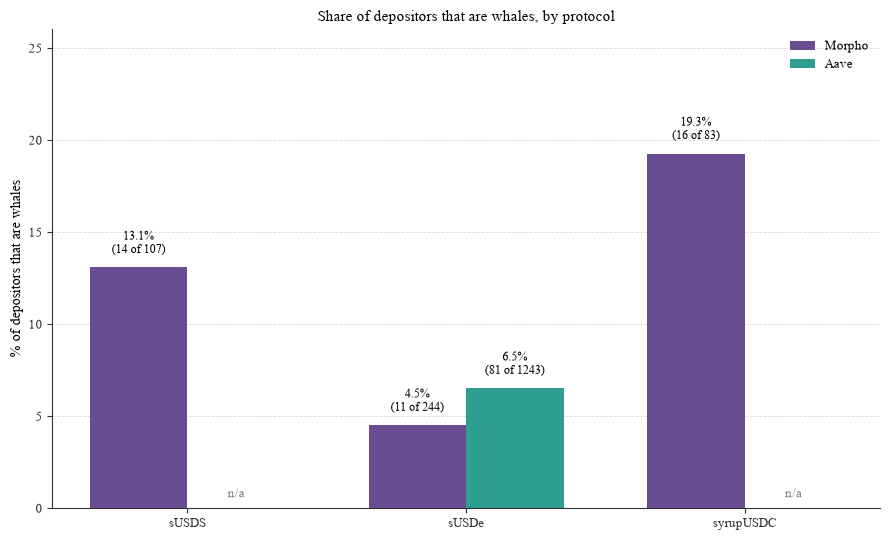

In [18]:
assets = ["sUSDS", "sUSDe", "syrupUSDC"]

# Morpho depositors: rows where YBS_in_morpho > 0
morpho_depositors = all_df[all_df["YBS_in_morpho"] > 0]
morpho_stats = (
    morpho_depositors.groupby("asset")["is_whale"]
    .agg(whales="sum", total="count")
)

# Aave depositors: rows where YBS_in_aave > 0
aave_depositors = all_df[all_df["YBS_in_aave"] > 0]
aave_stats = (
    aave_depositors.groupby("asset")["is_whale"]
    .agg(whales="sum", total="count")
)

morpho_vals, aave_vals = [], []
morpho_labels, aave_labels = [], []

for a in assets:
    if a in morpho_stats.index:
        whales_n = int(morpho_stats.loc[a, "whales"])
        total_n = int(morpho_stats.loc[a, "total"])
        pct = 100 * whales_n / total_n
        morpho_vals.append(pct)
        morpho_labels.append(f"{pct:.1f}%\n({whales_n} of {total_n})")
    else:
        morpho_vals.append(np.nan)
        morpho_labels.append(None)

    if a in aave_stats.index:
        whales_n = int(aave_stats.loc[a, "whales"])
        total_n = int(aave_stats.loc[a, "total"])
        pct = 100 * whales_n / total_n
        aave_vals.append(pct)
        aave_labels.append(f"{pct:.1f}%\n({whales_n} of {total_n})")
    else:
        aave_vals.append(np.nan)
        aave_labels.append(None)

morpho_vals = np.array(morpho_vals)
aave_vals = np.array(aave_vals)

fig, ax = plt.subplots(figsize=(9, 5.5))

x = np.arange(len(assets))
w = 0.35

ax.bar(x - w/2, morpho_vals, width=w, color=MORPHO_COLOR, label="Morpho")
ax.bar(x + w/2, np.nan_to_num(aave_vals), width=w, color=AAVE_COLOR, label="Aave")

for i in range(len(assets)):
    if not np.isnan(morpho_vals[i]):
        ax.text(x[i] - w/2, morpho_vals[i] + 0.6, morpho_labels[i], ha="center", fontsize=8.5, va="bottom")
    if not np.isnan(aave_vals[i]):
        ax.text(x[i] + w/2, aave_vals[i] + 0.6, aave_labels[i], ha="center", fontsize=8.5, va="bottom")
    else:
        ax.text(x[i] + w/2, 0.6, "n/a", ha="center", fontsize=9, color="gray")

ax.set_xticks(x)
ax.set_xticklabels(assets)
ax.set_ylabel("% of depositors that are whales")
ax.set_title("Share of depositors that are whales, by protocol")
ax.set_ylim(0, np.nanmax(np.concatenate([morpho_vals, aave_vals])) * 1.35)
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig("../output/whale_pct_by_protocol.png", dpi=300, bbox_inches="tight")
plt.show()
